# FXA logD: faithfulness results

In [1]:

from mol_faith.notebooks.results_analysis.shared import (
    REAL_WORLD_DATASETS,
    REAL_WORLD_RESULTS,
    REAL_WORLD_TARGET_COLORS,
    calculate_stats_by_method_target,
    combine_and_calculate_variance,
    compute_correlation_summary,
    compute_k_effect,
    create_grouped_boxplot,
    load_raw_data,
    load_raw_data_all_thres,
    pair_xai_methods,
    plot_boxplot_grid_by_model,
    plot_correlation_heatmap,
    plot_k_effect_bars,
    plot_negative_deviations,
    plot_std_by_method_target,
    process_fidelity_df,
)

In [2]:
DATASET = 'FXA_logD'
FOLDER, TARGET_NAME = REAL_WORLD_DATASETS[DATASET]
BASE_DIR = REAL_WORLD_RESULTS / FOLDER
OUTPUT_DIR = BASE_DIR / 'result_plots'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Load data

In [3]:
fid_df = process_fidelity_df(load_raw_data(BASE_DIR, TARGET_NAME))
fid_all_thres_df = process_fidelity_df(load_raw_data_all_thres(BASE_DIR, TARGET_NAME))
target_data = {DATASET: fid_df}

logd: 17,496 rows | models ['CNN', 'GAT', 'GCN', 'GIN', 'Transformer'] | methods ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling'] | thresholds [0.2]
14,996 rows | {'faithful': 10227, 'unfaithful': 4769} | normalized_fid in [-1.000, 1.000]


logd: 157,464 rows | models ['CNN', 'GAT', 'GCN', 'GIN', 'Transformer'] | methods ['gnn_explainer', 'grad_cam', 'graph_mask', 'guided_grad_cam', 'integrated_gradients', 'kernel_shap', 'lime', 'random_explanation', 'shap_sampling'] | thresholds [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
134,964 rows | {'faithful': 87809, 'unfaithful': 47155} | normalized_fid in [-1.000, 1.000]


## Fid+ by xAI method and model

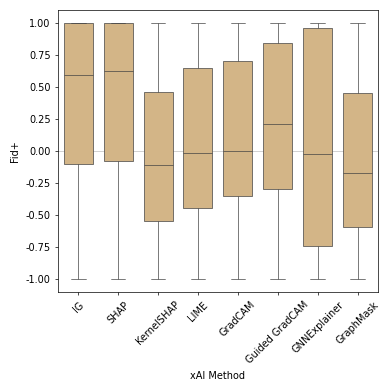

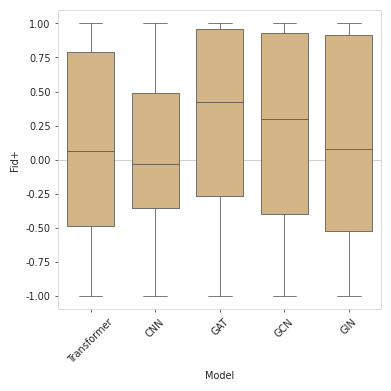

In [4]:
for group_col in ('explanation_method', 'model'):
    create_grouped_boxplot(target_data, value_col='normalized_fid', group_col=group_col, figsize=(4, 4),
                           target_colors=REAL_WORLD_TARGET_COLORS, output_dir=OUTPUT_DIR)

## xAI methods per model

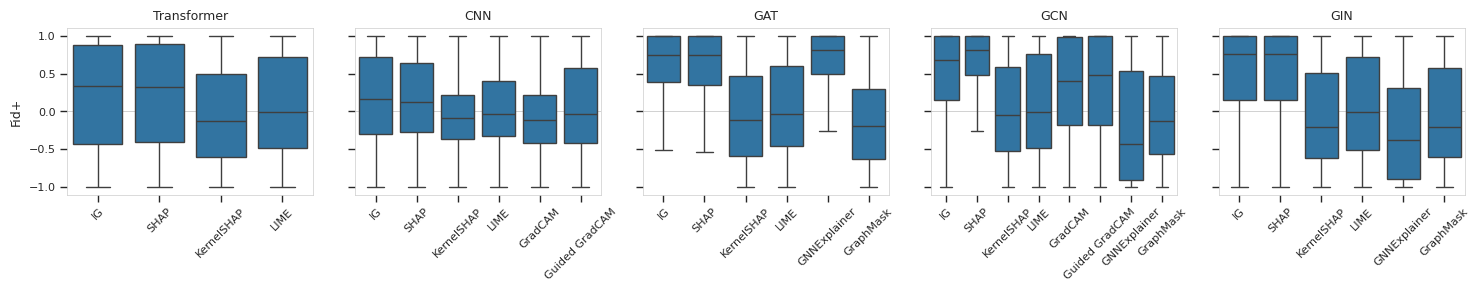

In [5]:
plot_boxplot_grid_by_model(fid_df, output_dir=OUTPUT_DIR);

## Summary table & standard deviation

In [6]:
variance_df = combine_and_calculate_variance(target_data)
variance_df

,model,explanation_method,target,n,mean,median,std,var
19,GCN,SHAP,FXA_logD,500,0.580,0.816,0.569,0.323
6,GAT,GNNExplainer,FXA_logD,500,0.578,0.805,0.603,0.364
22,GIN,IG,FXA_logD,500,0.474,0.764,0.643,0.413
25,GIN,SHAP,FXA_logD,500,0.482,0.761,0.632,0.400
8,GAT,IG,FXA_logD,500,0.557,0.747,0.552,0.305
11,GAT,SHAP,FXA_logD,500,0.547,0.742,0.557,0.310
16,GCN,IG,FXA_logD,500,0.460,0.676,0.612,0.374
15,GCN,Guided GradCAM,FXA_logD,496,0.310,0.479,0.669,0.448
13,GCN,GradCAM,FXA_logD,500,0.278,0.406,0.666,0.443
26,Transformer,IG,FXA_logD,500,0.179,0.337,0.710,0.505


In [7]:
calculate_stats_by_method_target(target_data)

,explanation_method,target,n,median,std,var
0,GNNExplainer,FXA_logD,1500,-0.028541,0.789079,0.622646
1,GradCAM,FXA_logD,1000,-0.001374,0.640884,0.410732
2,GraphMask,FXA_logD,1500,-0.174622,0.666184,0.443801
3,Guided GradCAM,FXA_logD,996,0.205346,0.667680,0.445796
4,IG,FXA_logD,2500,0.588433,0.650987,0.423784
5,KernelSHAP,FXA_logD,2500,-0.109069,0.652827,0.426183
6,LIME,FXA_logD,2500,-0.019253,0.669299,0.447961
7,SHAP,FXA_logD,2500,0.622880,0.645951,0.417252


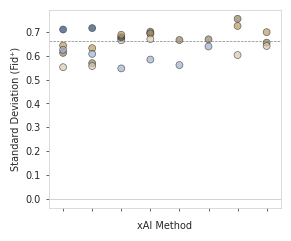

In [8]:
plot_std_by_method_target(variance_df, output_dir=OUTPUT_DIR);

## Parameter k analysis

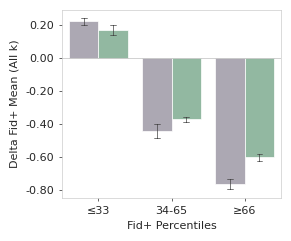

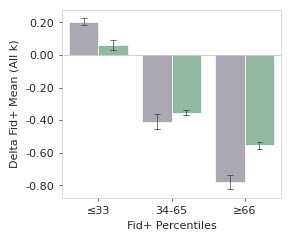

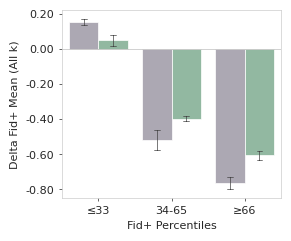

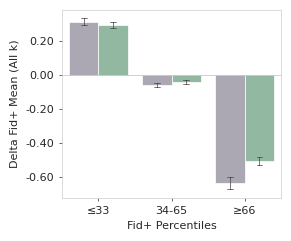

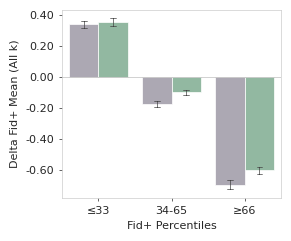

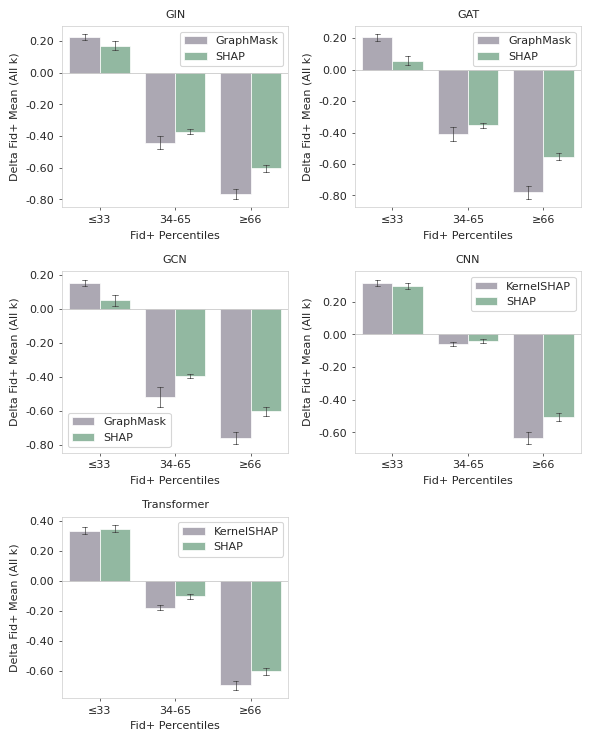

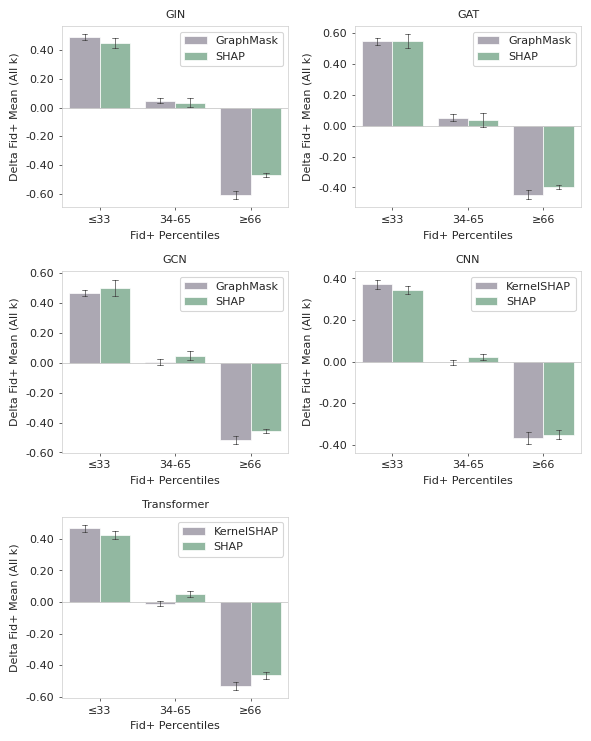

In [9]:
k_effect_df = compute_k_effect(fid_all_thres_df)
plot_k_effect_bars(k_effect_df, OUTPUT_DIR)

### Negative deviation

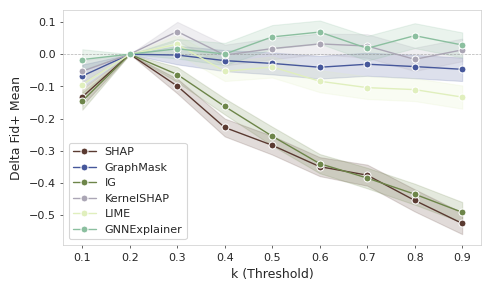

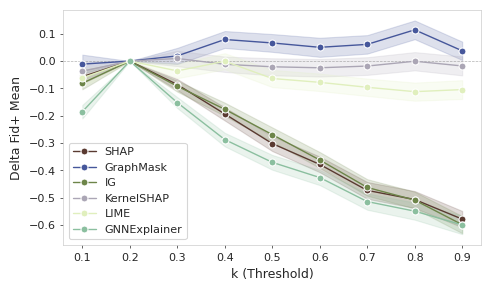

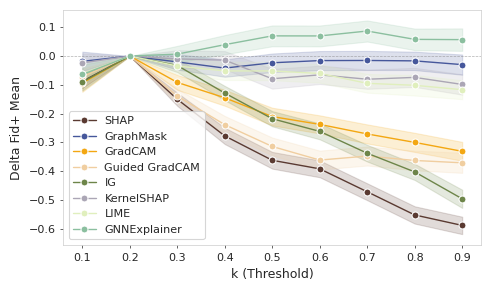

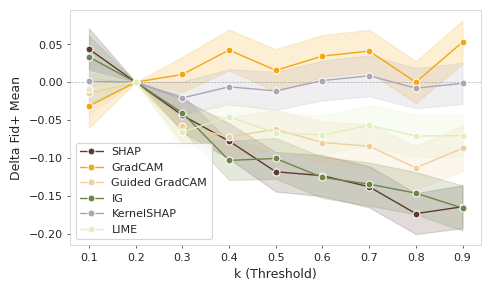

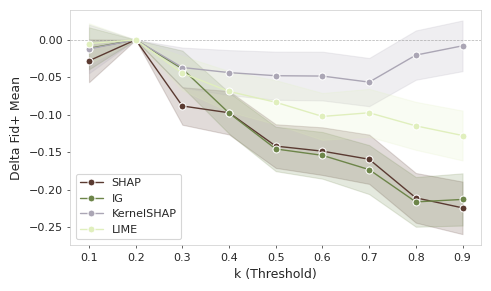

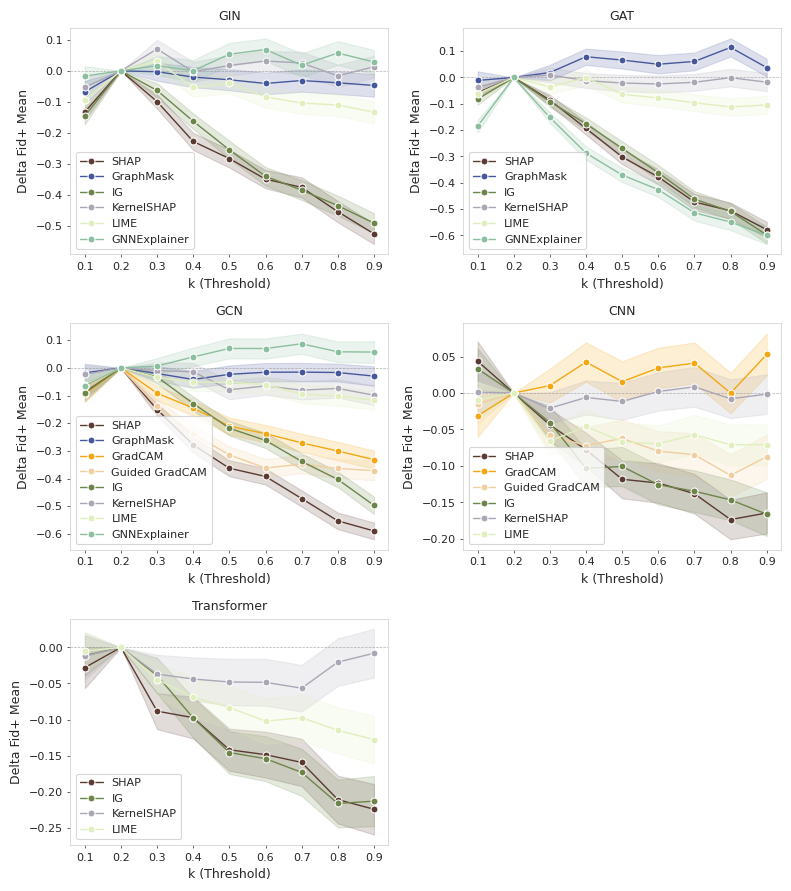

In [10]:
plot_negative_deviations(k_effect_df, OUTPUT_DIR)

## IG vs SHAP agreement

Per-molecule Normalized Fid+ of `integrated_gradients` and `shap_sampling` (same model, smiles, data split) are paired and correlated, to see whether "hard to explain" molecules are intrinsic to the molecule/model or an artifact of the xAI method.

,task,model,n,pearson_r,pearson_p,spearman_r,spearman_p
0,FXA_logD,CNN,500,0.665487,2.961317e-65,0.679204,6.635953e-69
1,FXA_logD,GAT,500,0.830931,6.708975e-129,0.902649,1.795043e-184
2,FXA_logD,GCN,500,0.475736,1.330432e-29,0.591103,1.970903e-48
3,FXA_logD,GIN,500,0.650454,1.797407e-61,0.751431,5.595205e-92
4,FXA_logD,Transformer,500,0.748529,6.689812e-91,0.766629,7.092116e-98


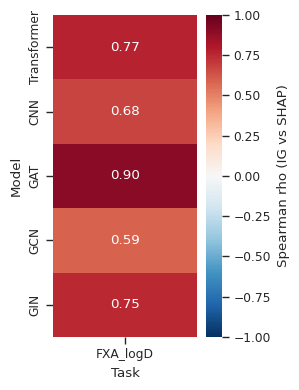

In [11]:
ig_shap_df = pair_xai_methods(fid_df).assign(task=DATASET)
ig_shap_corr_df = compute_correlation_summary(ig_shap_df, ['task', 'model'], 'normalized_fid_ig', 'normalized_fid_shap')
plot_correlation_heatmap(ig_shap_corr_df, output_dir=OUTPUT_DIR)
ig_shap_corr_df

### KernelSHAP vs SHAP agreement

,task,model,n,pearson_r,pearson_p,spearman_r,spearman_p
0,FXA_logD,CNN,500,0.409718,1.159198e-21,0.386310,3.047246e-19
1,FXA_logD,GAT,500,0.297213,1.175960e-11,0.341976,3.659652e-15
2,FXA_logD,GCN,500,0.199559,6.911321e-06,0.295749,1.497617e-11
3,FXA_logD,GIN,500,0.278773,2.236611e-10,0.361820,6.542241e-17
4,FXA_logD,Transformer,500,0.453134,1.096652e-26,0.473263,2.842921e-29


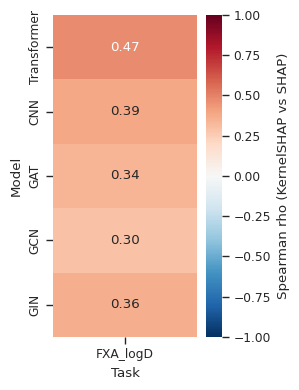

In [12]:
kernel_shap_df = pair_xai_methods(fid_df, method_a='kernel_shap', label_a='kernel_shap').assign(task=DATASET)
kernel_shap_corr_df = compute_correlation_summary(
    kernel_shap_df, ['task', 'model'], 'normalized_fid_kernel_shap', 'normalized_fid_shap'
)
plot_correlation_heatmap(kernel_shap_corr_df, cbar_label='Spearman rho (KernelSHAP vs SHAP)', output_dir=OUTPUT_DIR,
                         filename='kernel_shap_vs_shap_correlation_heatmap')
kernel_shap_corr_df

## Model comparison

In [13]:
# comparison_csv = BASE_DIR / 'multi_model_comparison.csv'
# format_multi_model_comparison_table(comparison_csv)

In [14]:
# print(format_latex_model_comparison_table(
#     comparison_csv,
#     caption='Model performance for the FXA logD task.',
#     label='tab:model_perf_fxa_logd',
# ))